In [1]:
import pandas as pd
from sklearn.datasets import load_digits
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from umap import UMAP

In [2]:
digits = load_digits()

In [3]:
X = digits.data
y = digits.target

In [4]:
print(f"\nData shape: {X.shape}")
print(f"\nTarget shape: {y.shape}")
print(f"\nDigit classes: {sorted(set(y))}")


Data shape: (1797, 64)

Target shape: (1797,)

Digit classes: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]


In [5]:
for i in range(10):
    print(X[i])

[ 0.  0.  5. 13.  9.  1.  0.  0.  0.  0. 13. 15. 10. 15.  5.  0.  0.  3.
 15.  2.  0. 11.  8.  0.  0.  4. 12.  0.  0.  8.  8.  0.  0.  5.  8.  0.
  0.  9.  8.  0.  0.  4. 11.  0.  1. 12.  7.  0.  0.  2. 14.  5. 10. 12.
  0.  0.  0.  0.  6. 13. 10.  0.  0.  0.]
[ 0.  0.  0. 12. 13.  5.  0.  0.  0.  0.  0. 11. 16.  9.  0.  0.  0.  0.
  3. 15. 16.  6.  0.  0.  0.  7. 15. 16. 16.  2.  0.  0.  0.  0.  1. 16.
 16.  3.  0.  0.  0.  0.  1. 16. 16.  6.  0.  0.  0.  0.  1. 16. 16.  6.
  0.  0.  0.  0.  0. 11. 16. 10.  0.  0.]
[ 0.  0.  0.  4. 15. 12.  0.  0.  0.  0.  3. 16. 15. 14.  0.  0.  0.  0.
  8. 13.  8. 16.  0.  0.  0.  0.  1.  6. 15. 11.  0.  0.  0.  1.  8. 13.
 15.  1.  0.  0.  0.  9. 16. 16.  5.  0.  0.  0.  0.  3. 13. 16. 16. 11.
  5.  0.  0.  0.  0.  3. 11. 16.  9.  0.]
[ 0.  0.  7. 15. 13.  1.  0.  0.  0.  8. 13.  6. 15.  4.  0.  0.  0.  2.
  1. 13. 13.  0.  0.  0.  0.  0.  2. 15. 11.  1.  0.  0.  0.  0.  0.  1.
 12. 12.  1.  0.  0.  0.  0.  0.  1. 10.  8.  0.  0.  0.  8.  4.  5. 14

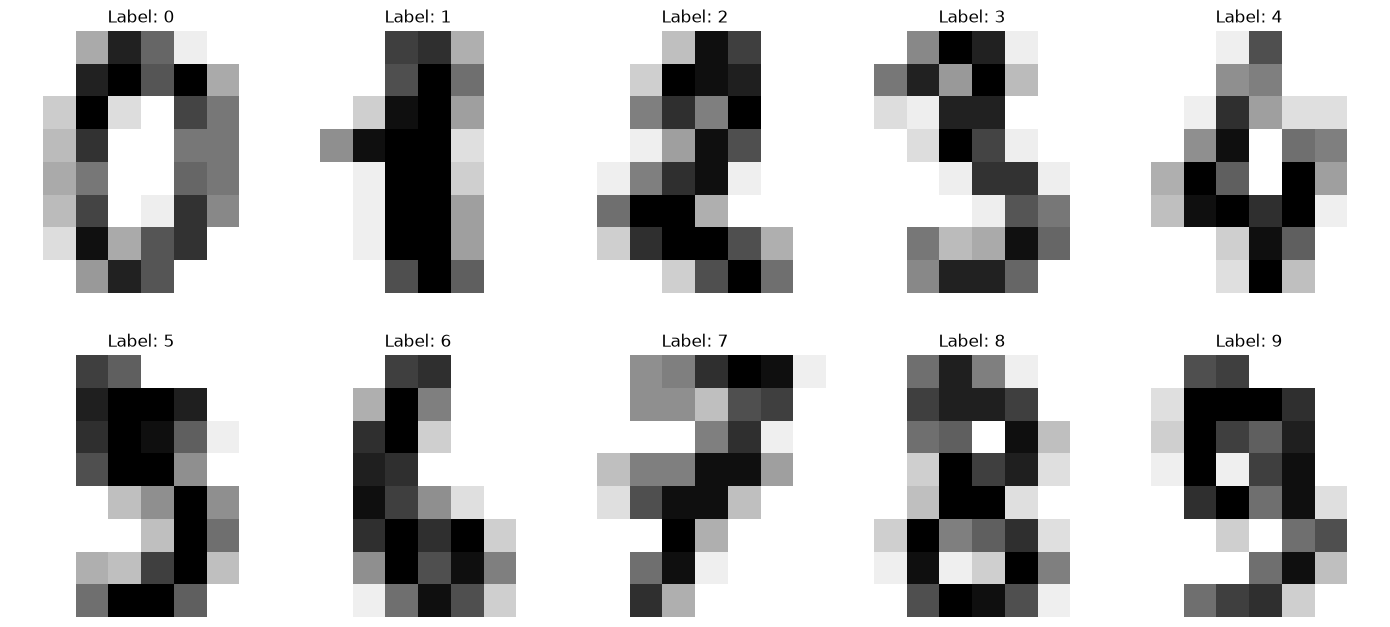

In [6]:
fig, axes = plt.subplots(2, 5, figsize=(14, 7))

for i, ax in enumerate(axes.flat):
    ax.imshow(digits.images[i], cmap="gray_r")
    ax.set_title(f"Label: {y[i]}")
    ax.axis("off")

plt.tight_layout()
plt.show() 

In [7]:
tsne = TSNE(
    n_components=2,
    random_state=42,
    perplexity=10,
    init="pca",
    learning_rate="auto"
)

X_tsne = tsne.fit_transform(X)

print(f"Original shape: {X.shape}")
print(f"t-sne shape: {X_tsne.shape}")

Original shape: (1797, 64)
t-sne shape: (1797, 2)


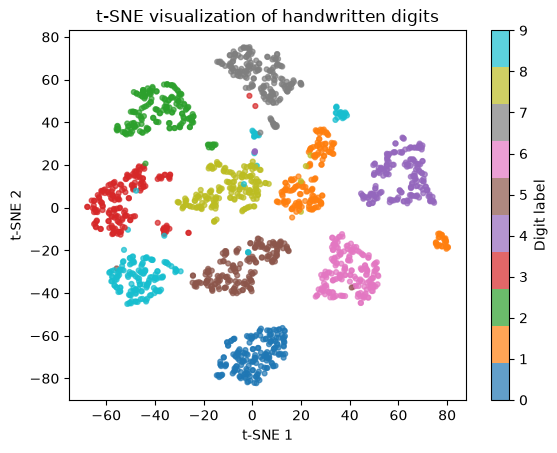

In [8]:
scatter = plt.scatter(
    X_tsne[:, 0],
    X_tsne[:, 1],
    c=y,
    cmap="tab10",
    s=12,
    alpha=0.7
)

plt.colorbar(scatter, ticks=range(10), label="Digit label")
plt.title("t-SNE visualization of handwritten digits")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.show()

In [10]:
umap_ = UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    random_state=42,
    compatibility_layout=False
)

X_umap_ = umap_.fit_transform(X)

print(f"\nOriginal shape: {X.shape}")
print(f"\nOriginal shape: {X_umap_.shape}")


Original shape: (1797, 64)

Original shape: (1797, 2)


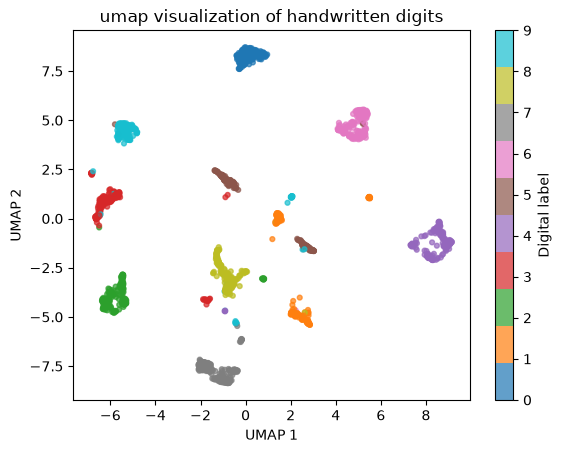

In [11]:
scatter_ = plt.scatter(
    X_umap_[:,0],
    X_umap_[:,1],
    c=y,
    cmap="tab10",
    s=12,
    alpha=0.7
)

plt.colorbar(scatter_, ticks=range(10), label="Digital label")
plt.title("umap visualization of handwritten digits")
plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.show()

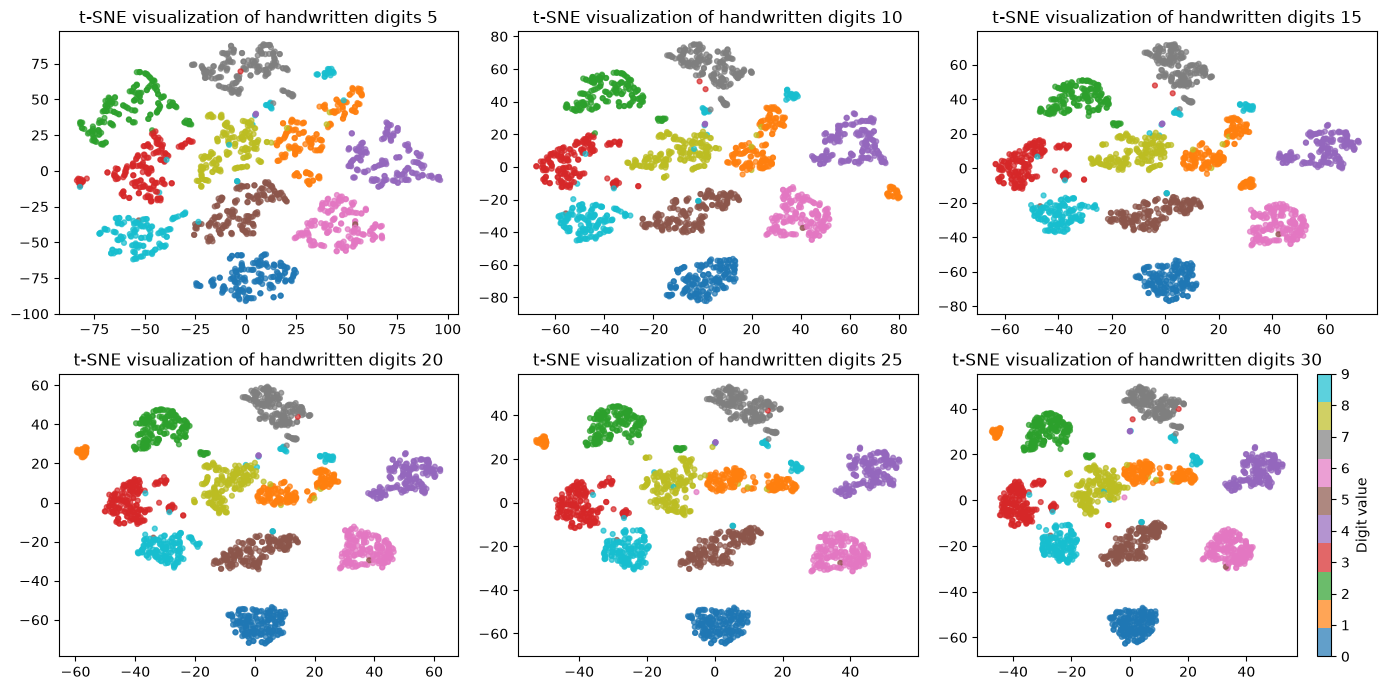

In [19]:
perplex = [5, 10, 15, 20, 25, 30]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))

for p, ax in zip(perplex, axes.flatten()):
    candidate = TSNE(
        n_components=2,
        random_state=42,
        perplexity=p,
        init="pca",
        learning_rate="auto"
    )

    X_candidate = candidate.fit_transform(X)

    scatter= ax.scatter(
        X_candidate[:,0],
        X_candidate[:,1],
        c=y,
        cmap="tab10",
        s=12,
        alpha=0.7
    )

    ax.set_title(f"t-SNE visualization of handwritten digits {p}")

fig.colorbar(scatter, ticks=range(10), label="Digit value")
plt.tight_layout()  
plt.show()
    